In [1]:
import numpy as np
import pandas as pd
import anndata as ad
import os
import sys
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
%matplotlib inline

In [3]:
notes = pd.read_table('../Model_Runs/model_run_notes.txt')

In [4]:
notes.head()

,Runs for included model inputs are as follows:
0,"Low stiffness, +ERL"
1,"erl_7-7_1_1.csv, erl_7-7_1_2.csv, erl_7-7_1_3.csv"
2,"Int. stiffness, +ERL"
3,"erl_7-7_2_1.csv, erl_7-7_2_2.csv, erl_7-7_2_3.csv"
4,"High stiffness, +ERL"


In [5]:
cn = notes.iloc[13:37,0].to_list()
cn = [x.split(" ")[1] for x in cn]

In [6]:
cn

['Skp2',
 'p21',
 'p21p',
 'Cdh1',
 'Myc',
 'CycD',
 'CycDp21',
 'Rb',
 'pRb',
 'E2F',
 'RbE2F',
 'CycE',
 'CycEp21',
 'CycA',
 'CycAp21',
 'CycB',
 'CycBp21',
 'Cdc20',
 'BAX',
 'BAXmBCL2',
 'BH3',
 'BH3BCL2',
 'BAXm',
 'BCL2']

In [7]:
file_names = [x for x in os.listdir('../Model_Runs') if not "txt" in x]

In [8]:
file_names

['dmso_7-7_3.csv',
 'erl_7-7_3_1.csv',
 'erl_7-7_3_2.csv',
 'erl_7-7_2_1.csv',
 'st_t.csv',
 'erl_7-7_2_2.csv',
 'erl_7-7_3_3.csv',
 'dmso_7-7_2.csv',
 'erl_7-7_2_3.csv',
 'erl_7-7_1_3.csv',
 'erl_7-7_1_2.csv',
 'dmso_7-7_1.csv',
 'erl_7-7_1_1.csv']

In [9]:
a = pd.read_csv(os.path.join('../Model_Runs',file_names[0]), header=None, names=cn)

In [10]:
a.head()

,Skp2,p21,p21p,Cdh1,Myc,CycD,CycDp21,Rb,pRb,E2F,...,CycAp21,CycB,CycBp21,Cdc20,BAX,BAXmBCL2,BH3,BH3BCL2,BAXm,BCL2
0,15.0,8.0,5.0000,3.0,94.0,39.0,3.0,97.00,74.000,4.00000,...,13.0,153.0,1.0,156.0,200.0,0.0,0.0,7.0,0.0,183.0
1,15.0,7.0,5.0000,5.0,99.0,35.0,4.0,100.53,70.468,3.00000,...,13.0,154.0,1.0,164.0,200.0,0.0,0.0,7.0,0.0,183.0
2,15.0,8.0,6.0000,2.0,99.0,36.0,3.0,113.00,54.599,0.59859,...,12.0,152.0,1.0,169.0,198.0,2.0,0.0,7.0,0.0,181.0
3,15.0,7.0,6.0000,2.0,96.0,35.0,3.0,112.70,59.300,6.00000,...,13.0,151.0,1.0,170.0,197.0,3.0,0.0,7.0,0.0,180.0
4,15.0,10.0,2.7665,6.0,102.0,39.0,3.0,111.00,56.000,1.00000,...,15.0,152.0,1.0,178.0,196.0,4.0,0.0,7.0,0.0,179.0


In [11]:
a.insert(0, "time", a.index*0.1)

In [12]:
a.head()

,time,Skp2,p21,p21p,Cdh1,Myc,CycD,CycDp21,Rb,pRb,...,CycAp21,CycB,CycBp21,Cdc20,BAX,BAXmBCL2,BH3,BH3BCL2,BAXm,BCL2
0,0.0,15.0,8.0,5.0000,3.0,94.0,39.0,3.0,97.00,74.000,...,13.0,153.0,1.0,156.0,200.0,0.0,0.0,7.0,0.0,183.0
1,0.1,15.0,7.0,5.0000,5.0,99.0,35.0,4.0,100.53,70.468,...,13.0,154.0,1.0,164.0,200.0,0.0,0.0,7.0,0.0,183.0
2,0.2,15.0,8.0,6.0000,2.0,99.0,36.0,3.0,113.00,54.599,...,12.0,152.0,1.0,169.0,198.0,2.0,0.0,7.0,0.0,181.0
3,0.3,15.0,7.0,6.0000,2.0,96.0,35.0,3.0,112.70,59.300,...,13.0,151.0,1.0,170.0,197.0,3.0,0.0,7.0,0.0,180.0
4,0.4,15.0,10.0,2.7665,6.0,102.0,39.0,3.0,111.00,56.000,...,15.0,152.0,1.0,178.0,196.0,4.0,0.0,7.0,0.0,179.0


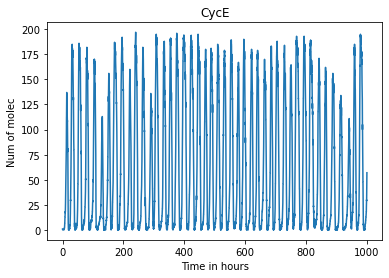

In [13]:
plt.plot(a.iloc[0:10000,]['time'],a.iloc[:10000,]['CycE'])
plt.title('CycE')
plt.xlabel('Time in hours')
plt.ylabel('Num of molec')
plt.show()

## cellXgene
For analysis using cellXgene (a project by the Chan-Zuckerberg Initiative), must get data in `anndata` format. See https://anndata.readthedocs.io/en/latest/